In [1]:
from Instruments.hp34461A import *
from Instruments.vna_config import *
from Instruments.power_supply import *
from Routines.res_to_temp import *
from Routines.retrieve_vna_data import *
from Routines.vna_analysis import *
from Instruments.power_supply import *
from Routines.dep_evap import *
from Routines.extraction_handling_pt import *


from scipy.optimize import brentq
import numpy as np
from datetime import datetime
import time, sys, os, pyvisa, subprocess
import matplotlib as mpl
import matplotlib.pyplot as plt
import time

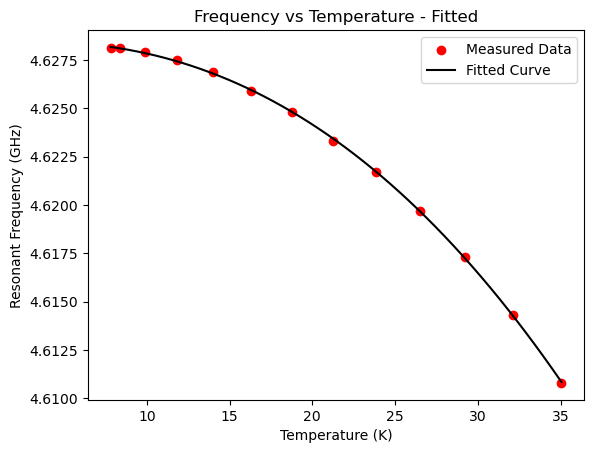

In [40]:
minus20 = {}

for folder in os.listdir(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026"):
    
    new_path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026" + '\\' + folder

    calibration_path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\calibration_05042026" + '\\' + "mode4"

    minus20[folder] = measuredData(new_path)

    minus20[folder].res_frequency_extraction()

    minus20[folder].calculate_calibration_parameters(calibration_path)






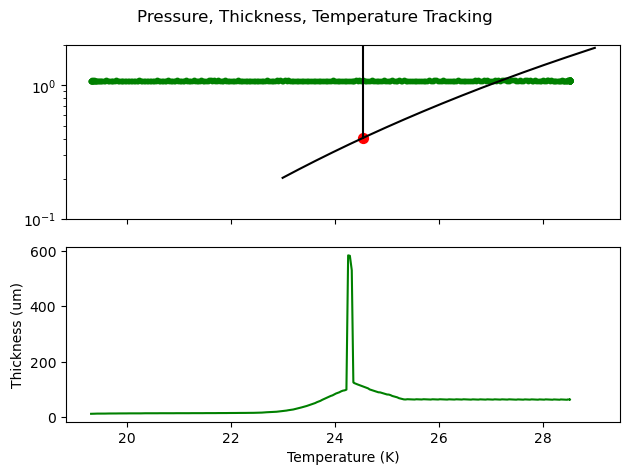

In [41]:
for vals in minus20.values():

    vals.normalized_frequency_extraction()

    vals.map_to_thickness(to_plot = True)

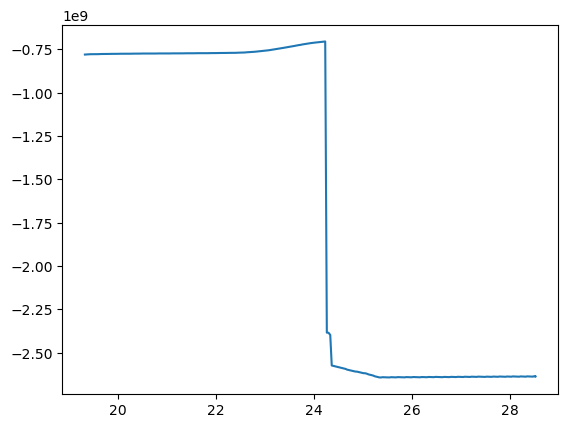

In [ ]:
fig, axes = plt.subplots(3,3, figsize = (13, 13), sharex = True)

layout = [
    [6, 7, 8],
    [5, 4, 3],
    [0, 1, 2]
]

for i in range(3):
    for j in range(3):
        to_plot = layout[i][j]
        pcm = axes[i, j].plot(minus20[f"mode{to_plot}"].data_dict["temperature"], minus20[f"mode{to_plot}"].thickness)
        axes[i, j].set_xlabel("Temperature (K)")
        axes[i, j].set_ylabel("Thickness (um)")
        axes[i, j].set_title(f"Mode {to_plot}")


fig.suptitle("Real time multires thickness monitor")
plt.tight_layout()
plt.show()


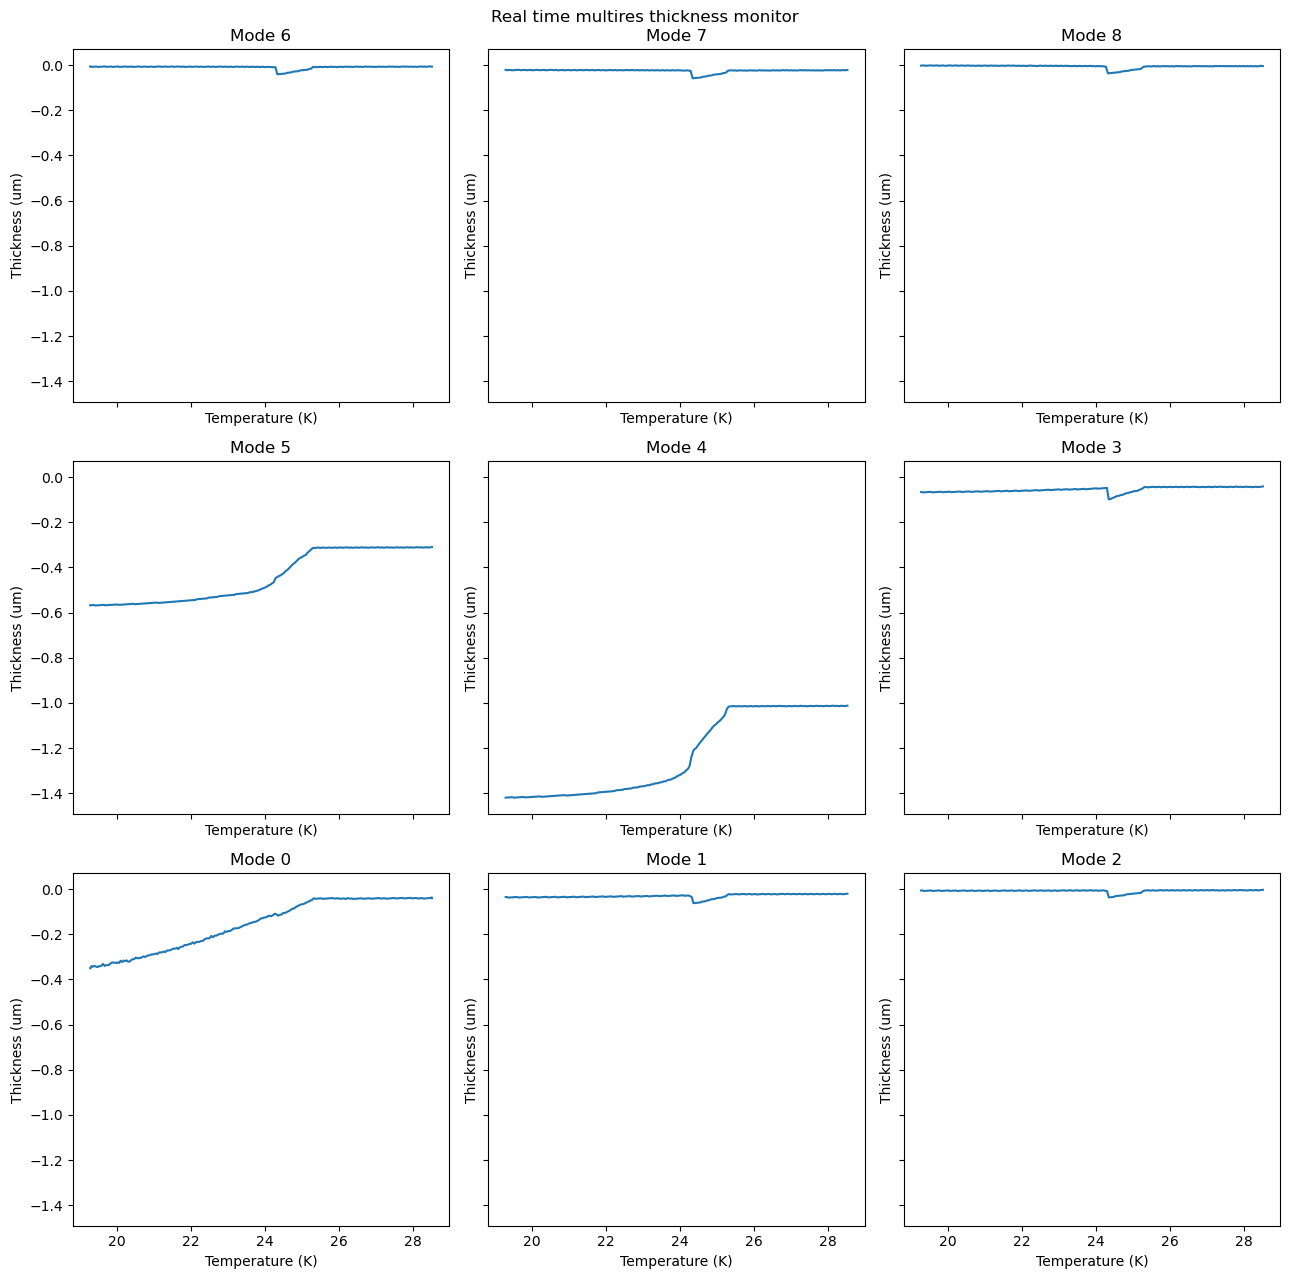

In [29]:
fig, axes = plt.subplots(3,3, figsize = (13, 13), sharex = True, sharey= True)

layout = [
    [6, 7, 8],
    [5, 4, 3],
    [0, 1, 2]
]

for i in range(3):
    for j in range(3):
        to_plot = layout[i][j]
        pcm = axes[i, j].plot(minus20[f"mode{to_plot}"].data_dict["temperature"], minus20[f"mode{to_plot}"].normalized_frequencies)
        axes[i, j].set_xlabel("Temperature (K)")
        axes[i, j].set_ylabel("Thickness (um)")
        axes[i, j].set_title(f"Mode {to_plot}")


fig.suptitle("Real time multires thickness monitor")
plt.tight_layout()
plt.show()


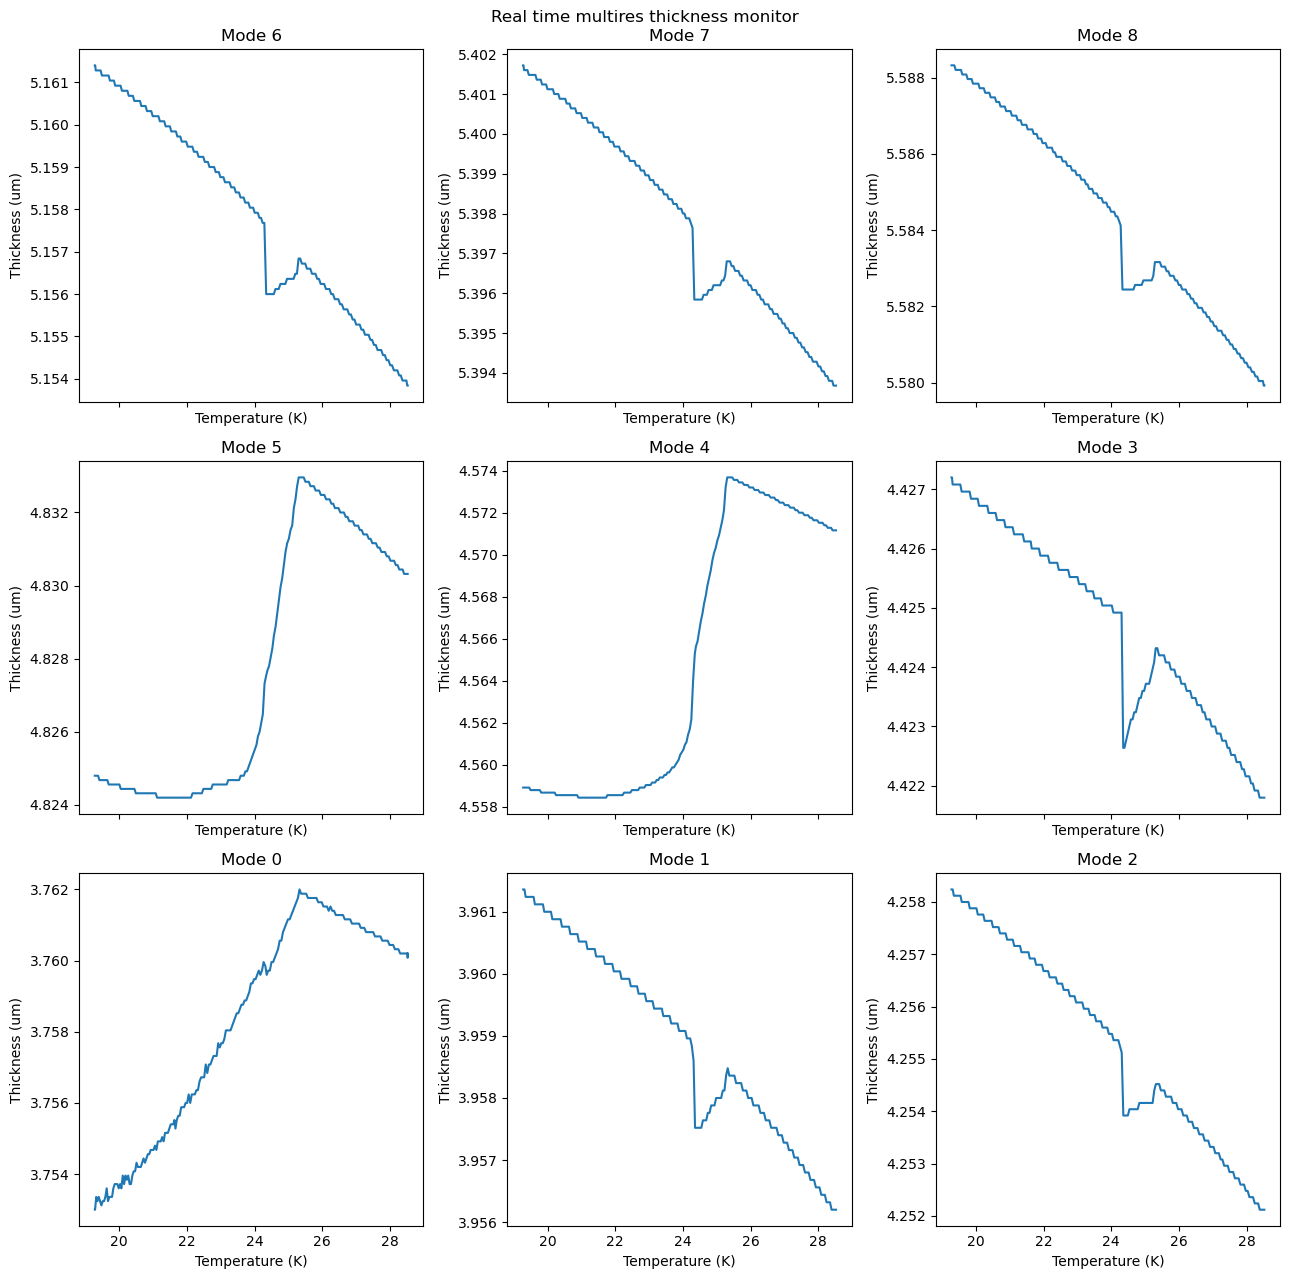

In [30]:
fig, axes = plt.subplots(3,3, figsize = (13, 13), sharex = True)

layout = [
    [6, 7, 8],
    [5, 4, 3],
    [0, 1, 2]
]

for i in range(3):
    for j in range(3):
        to_plot = layout[i][j]
        pcm = axes[i, j].plot(minus20[f"mode{to_plot}"].data_dict["temperature"], minus20[f"mode{to_plot}"].f0_list)
        axes[i, j].set_xlabel("Temperature (K)")
        axes[i, j].set_ylabel("Thickness (um)")
        axes[i, j].set_title(f"Mode {to_plot}")


fig.suptitle("Real time multires thickness monitor")
plt.tight_layout()
plt.show()


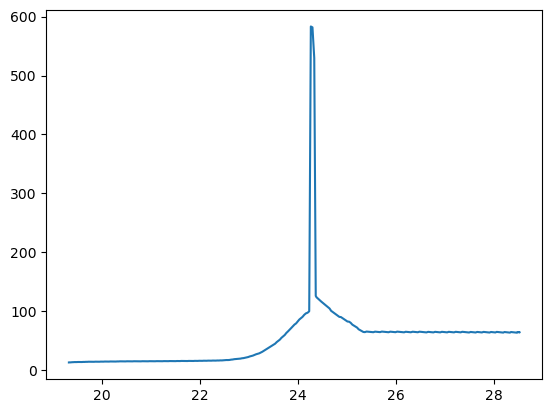

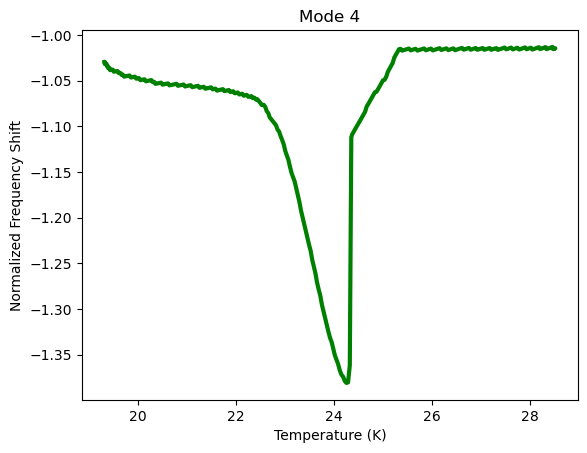

In [43]:

plt.plot(minus20["mode0"].data_dict["temperature"], minus20["mode0"].thickness)

plt.show()

plt.plot(minus20["mode0"].data_dict["temperature"], minus20["mode0"].normalized_frequencies, lw = 3, color = 'green')
plt.xlabel("Temperature (K)")
plt.ylabel("Normalized Frequency Shift")
plt.title("Mode 4")

plt.show()

[ 5.16561309e+00  1.55708003e-04 -1.65679340e-05 -1.01670906e-07]
[ 5.40702307e+00  1.67026395e-04 -1.79582822e-05 -9.94481621e-08]
[ 5.59283982e+00  1.62898609e-04 -1.80093364e-05 -1.14148671e-07]
[ 4.85608820e+00  1.35321983e-04 -1.53146069e-05 -9.24760659e-08]
[ 4.62823520e+00  9.90621885e-05 -1.26665432e-05 -1.23094626e-07]
[ 4.43358379e+00  1.17545789e-04 -1.35292760e-05 -9.84655296e-08]
[ 3.76851517e+00  7.52292427e-05 -8.14757558e-06 -1.02984204e-07]
[ 3.96559657e+00  1.43837782e-04 -1.39985157e-05 -5.63492580e-08]
[ 4.26184580e+00  1.23719828e-04 -1.38833747e-05 -7.88150523e-08]


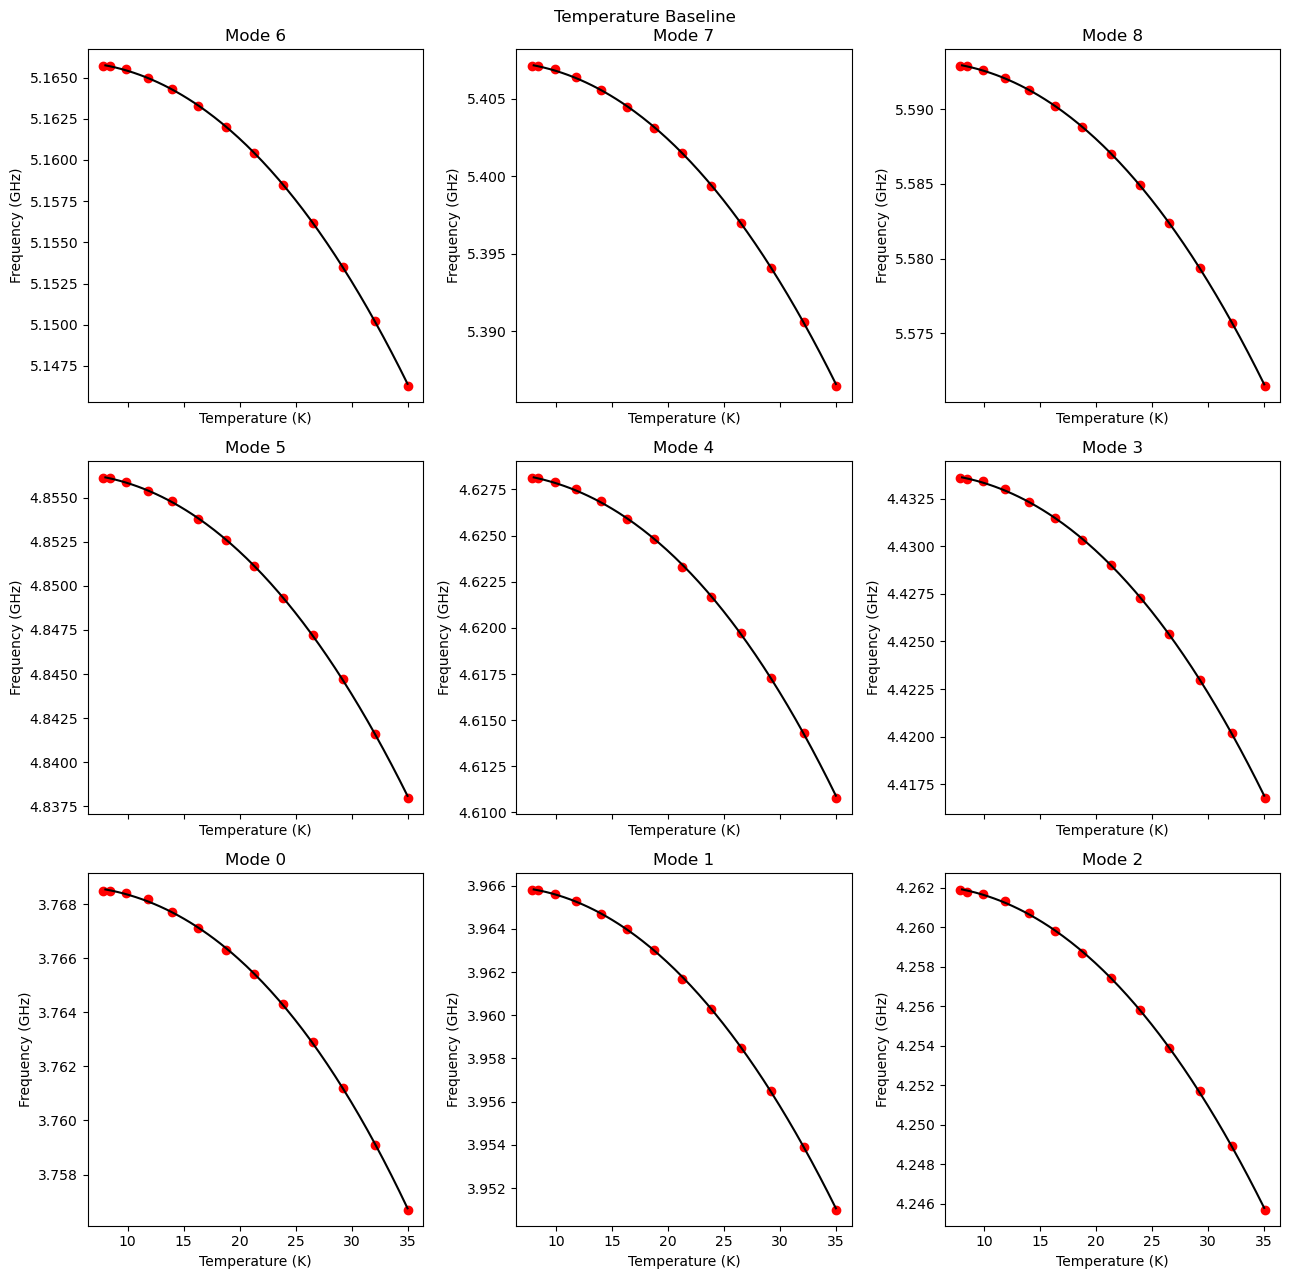

In [21]:

calibration_file = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\calibration_05042026"
f0_list = {}
T_list = {}

for file_name in (os.listdir(calibration_file)):

    f0_list[file_name] = []
    T_list[file_name] = []

    new_calibration_file = calibration_file + '\\' + file_name
    for actual_file in os.listdir(new_calibration_file):
        df = pd.read_csv(new_calibration_file + "\\" + actual_file)
        f_data = df.iloc[0, 1:].to_numpy()/1e9
        S_data = df.iloc[1, 1:].to_numpy()
        phase_data = df.iloc[2, 1:].to_numpy()
        L_data = 10**((S_data - np.max(S_data))/10)
        
        initial_split = (actual_file.split('_')[-3])
        T_val = float(initial_split.split(' ')[0])

        f_min = f_data[np.argmin(S_data)]

        f0_list[file_name].append(f_min)

        T_list[file_name].append(T_val)


x_fit = np.linspace(35, 8, 151)
fig, axes = plt.subplots(3,3, figsize = (13, 13), sharex = True)

layout = [
    [6, 7, 8],
    [5, 4, 3],
    [0, 1, 2]
]

for i in range(3):
    for j in range(3):
        to_plot = layout[i][j]
        axes[i, j].plot(x_fit, calibration_polynomial(x_fit, *minus20[f"mode{to_plot}"].calibration_parameters), color = 'black')
        print(minus20[f"mode{to_plot}"].calibration_parameters)
        axes[i, j].scatter(T_list[f"mode{to_plot}"], f0_list[f"mode{to_plot}"], color = 'red')
        axes[i, j].set_xlabel("Temperature (K)")
        axes[i, j].set_ylabel("Frequency (GHz)")
        axes[i, j].set_title(f"Mode {to_plot}")


fig.suptitle("Temperature Baseline")
plt.tight_layout()
plt.show()


In [19]:
for key in minus20.keys():

    print(minus20[key].calibration_parameters)


[ 3.76851517e+00  7.52292427e-05 -8.14757558e-06 -1.02984204e-07]
[ 3.96559657e+00  1.43837782e-04 -1.39985157e-05 -5.63492580e-08]
[ 4.26184580e+00  1.23719828e-04 -1.38833747e-05 -7.88150523e-08]
[ 4.43358379e+00  1.17545789e-04 -1.35292760e-05 -9.84655296e-08]
[ 4.62823520e+00  9.90621885e-05 -1.26665432e-05 -1.23094626e-07]
[ 4.85608820e+00  1.35321983e-04 -1.53146069e-05 -9.24760659e-08]
[ 5.16561309e+00  1.55708003e-04 -1.65679340e-05 -1.01670906e-07]
[ 5.40702307e+00  1.67026395e-04 -1.79582822e-05 -9.94481621e-08]
[ 5.59283982e+00  1.62898609e-04 -1.80093364e-05 -1.14148671e-07]


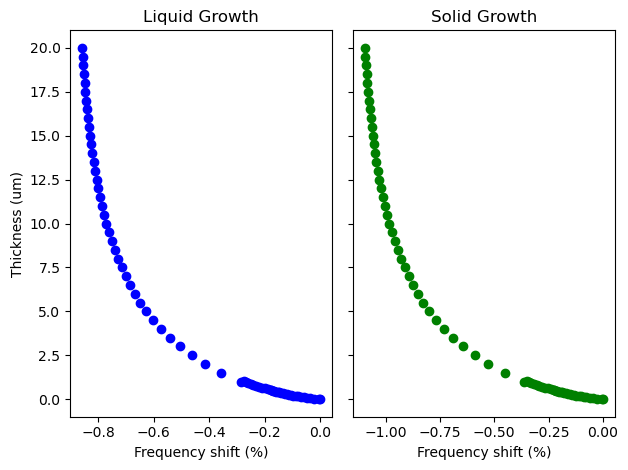

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)

ax1.scatter(liq_freq, liq_thickness, color = 'blue')
ax2.scatter(sol_freq, sol_thickness, color = 'green')
ax1.set_title("Liquid Growth")
ax2.set_title("Solid Growth")
ax1.set_ylabel("Thickness (um)")
ax1.set_xlabel("Frequency shift (%)")
ax2.set_xlabel("Frequency shift (%)")

plt.tight_layout()
plt.show()

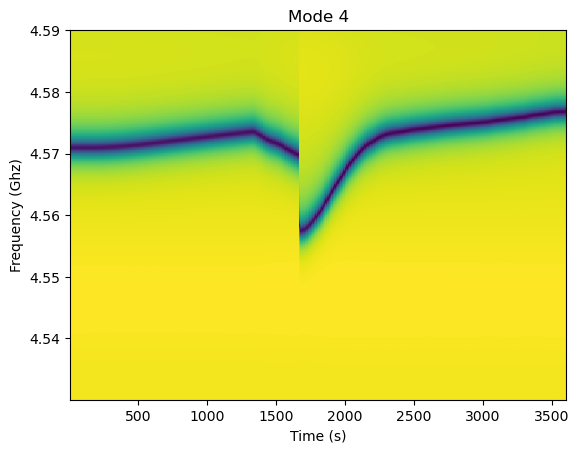

In [44]:
s21 = pd.read_csv(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026\mode0\2026-05-13 17_26_40.296537_S21_power10mode4focus.csv", delimiter = " ").to_numpy()[:, :-1]

freq = pd.read_csv(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026\mode0\2026-05-13 17_26_40.296537_frequency_power10mode4focus.csv", delimiter = " ").to_numpy().flatten()

time = pd.read_csv(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026\mode0\2026-05-13 17_26_40.296537_time_power10mode4focus.csv", delimiter = " ").to_numpy().flatten()


pcm = plt.pcolor(time, freq, s21)

plt.xlabel("Time (s)")
plt.ylabel("Frequency (Ghz)")
plt.title("Mode 4")
plt.show()